# Preliminary phenotyping of the chordoma TMA (CH)

Cells segmented in `01_Complete IMC Data Analysis Workflow.ipynb` are assigned to cell types by marker gating.

**Status: preliminary.** No artifact removal and no pathologist review have been applied; one threshold per marker is used for the whole array.

1. DNA status per core
2. Thresholds per marker
3. Doubtful cells
4. Gating rules
5. Tables
6. Figures

In [19]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tifffile

WORKFLOW_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
OUT = WORKFLOW_DIR / 'results' / 'phenotyping_preliminary'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'Arial', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})

ORDER = ['Tumour', 'Macrophage', 'Neutrophil', 'T cell', 'Dendritic cell', 'Endothelium',
         'aSMA+ stroma', 'Other cells', 'Doubtful', 'Low DNA']
COLOURS = {'Tumour': '#d62728', 'Macrophage': '#2ca02c', 'Neutrophil': '#ff7f0e', 'T cell': '#1f77b4',
           'Dendritic cell': '#9467bd', 'Endothelium': '#e377c2', 'aSMA+ stroma': '#8c564b',
           'Other cells': '#c7c7c7', 'Doubtful': '#7f7f7f', 'Low DNA': '#000000'}
SAMPLE_ORDER = ['High grade', 'Low grade', 'High infiltration', 'Tumour periphery', 'Tumour border', 'Non-neoplastic']

## 1. DNA status per core

A cell is low-DNA when arcsinh(DNA1) + arcsinh(DNA2) < 1. A core is valid below 20% low-DNA cells, intermediate at 20–50%, DNA-negative above 50%. DNA-negative cores and ROI117 (repeat acquisition of N7) are left out. Low-DNA cells in the remaining cores are labelled *Low DNA* and not phenotyped.

In [20]:
cells = pd.read_csv(WORKFLOW_DIR / 'data/cells.csv', low_memory=False)
cells = cells[cells['repeat_of'].isna()].copy()
cells['Image'] = cells['Image'].str.replace('.tiff', '', regex=False)

cells['low_dna'] = np.arcsinh(cells['DNA1']) + np.arcsinh(cells['DNA2']) < 1
frac = cells.groupby('Image')['low_dna'].mean()
status = pd.cut(frac, [-1, 0.2, 0.5, 1.1], labels=['valid', 'intermediate', 'dna_negative']).astype(str)
cells['dna_status'] = cells['Image'].map(status)
print(status.value_counts())

df = cells[cells['dna_status'] != 'dna_negative'].copy()
print(len(df), 'cells in', df['Image'].nunique(), 'cores')

low_dna
valid           122
dna_negative     24
intermediate      5
Name: count, dtype: int64
166082 cells in 127 cores


## 2. Thresholds per marker

A cell is positive for a marker when its mean count is above the threshold. Thresholds are read from the arcsinh histograms: Brachyury 1 count and S100 3 counts (dip between the negative and positive populations); all other markers 2 counts. CD56 is not used: most cells, including tumour cells, are CD56 positive.

,threshold_counts,percent_positive
Brachiury,1,38.5
S100,3,30.0
CD68,2,7.7
CD163,2,5.0
CD3,2,0.1
CD4,2,2.6
CD8,2,1.9
CD31,2,0.7
aSMA,2,18.2
CD66b,2,1.6


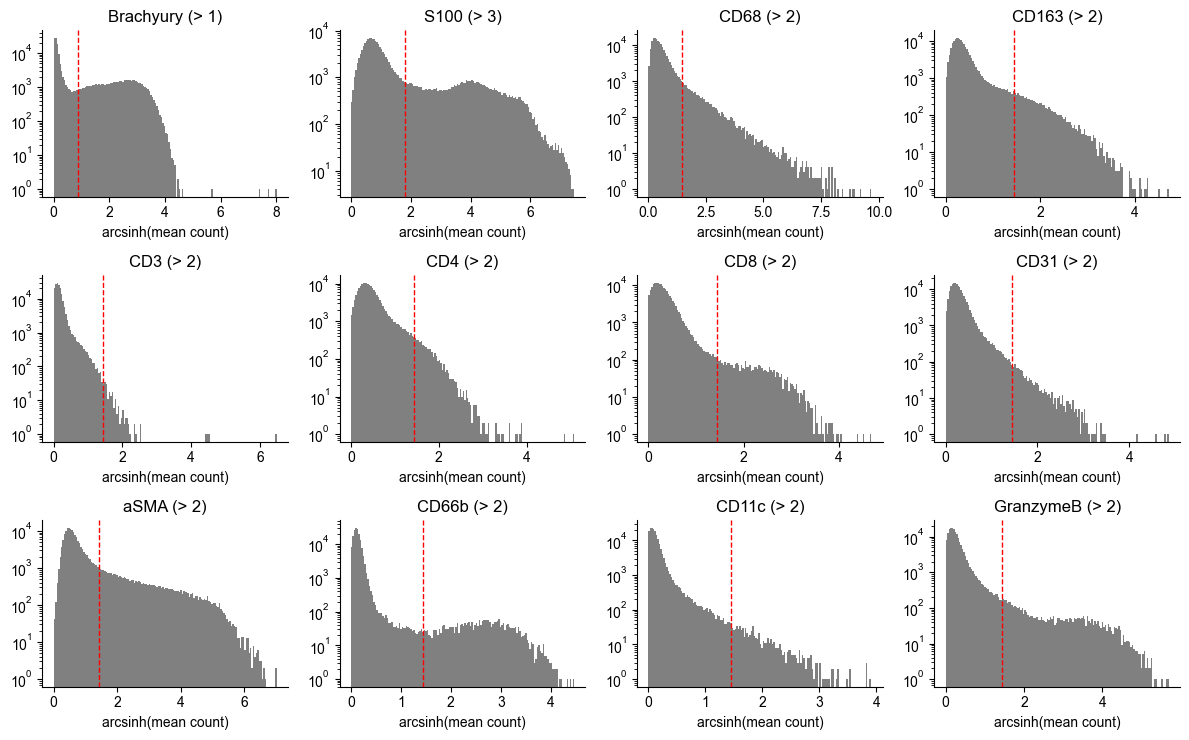

In [21]:
THRESHOLD = {'Brachiury': 1, 'S100': 3}
thr = lambda m: THRESHOLD.get(m, 2)
LINEAGE = ['Brachiury', 'S100', 'CD68', 'CD163', 'CD3', 'CD4', 'CD8', 'CD31', 'aSMA', 'CD66b', 'CD11c']
SHOWN = LINEAGE + ['GranzymeB']

fig, axs = plt.subplots(3, 4, figsize=(12, 7.5))
for ax, m in zip(axs.ravel(), SHOWN):
    ax.hist(np.arcsinh(df[m]), bins=150, color='grey')
    ax.set_yscale('log')
    ax.axvline(np.arcsinh(thr(m)), color='red', lw=1, ls='--')
    ax.set_title(f"{m.replace('Brachiury', 'Brachyury')} (> {thr(m)})")
    ax.set_xlabel('arcsinh(mean count)')
fig.tight_layout()
fig.savefig(OUT / 'histograms_thresholds.png', dpi=200, bbox_inches='tight')

thresholds = pd.DataFrame({'threshold_counts': [thr(m) for m in SHOWN],
                           'percent_positive': [round((df[m] > thr(m)).mean() * 100, 1) for m in SHOWN]},
                          index=SHOWN)
thresholds.to_csv(OUT / 'thresholds.csv')
thresholds

## 3. Doubtful cells

A cell above 2 counts for 4 or more lineage markers is treated as an aggregate or spillover and labelled *Doubtful*.

In [22]:
pos = lambda m: df[m].to_numpy() > thr(m)
neg = lambda m: ~pos(m)
doubtful = (df[LINEAGE] > 2).sum(axis=1).to_numpy() >= 4
print(doubtful.sum(), 'doubtful cells')

1482 doubtful cells


## 4. Gating rules

Rules are applied from top to bottom; the first match wins. Cells matching no rule are *Other cells*.

In [23]:
rules = {
    'Low DNA': df['low_dna'].to_numpy(),
    'Doubtful': doubtful,
    'T cell': (df['CD3'].to_numpy() > 1) & (pos('CD4') | pos('CD8')) & neg('CD68') & neg('Brachiury'),
    'Neutrophil': pos('CD66b') & neg('CD68') & neg('Brachiury'),
    'Macrophage': (pos('CD68') | pos('CD163')) & neg('Brachiury'),
    'Dendritic cell': pos('CD11c') & neg('Brachiury') & neg('S100'),
    'Endothelium': pos('CD31') & neg('aSMA') & neg('Brachiury') & neg('S100'),
    'Tumour': pos('Brachiury') | (pos('S100') & neg('aSMA')),
    'aSMA+ stroma': pos('aSMA') & neg('Brachiury'),
}
df['phenotype'] = np.select(list(rules.values()), list(rules.keys()), 'Other cells')
df['phenotype'].value_counts()

phenotype
Tumour            74372
Other cells       46380
aSMA+ stroma      25856
Macrophage        12978
Neutrophil         2102
Doubtful           1418
Low DNA            1382
T cell             1342
Dendritic cell      144
Endothelium         108
Name: count, dtype: int64

## 5. Tables

- `preliminary_phenotypes.csv`: one row per cell.
- `phenotypes_per_core.csv`: % of phenotyped cells per core (*Low DNA* and *Doubtful* excluded from the denominator).

In [24]:
df[['Image', 'Object', 'key_label', 'patient_id', 'core', 'sample_type', 'dna_status',
    'centroid-0', 'centroid-1', 'area', 'phenotype']].to_csv(OUT / 'preliminary_phenotypes.csv', index=False)

ph = df[~df['phenotype'].isin(['Low DNA', 'Doubtful'])]
per_core = pd.crosstab(ph['Image'], ph['phenotype'], normalize='index').mul(100).round(1)
per_core = per_core[[o for o in ORDER if o in per_core.columns]]
info = df.groupby('Image')[['key_label', 'patient_id', 'core', 'sample_type', 'dna_status']].first()
per_core = info.join(df.groupby('Image').size().rename('cells')).join(per_core)
per_core.to_csv(OUT / 'phenotypes_per_core.csv')
per_core.head()

,key_label,patient_id,core,sample_type,dna_status,cells,Tumour,Macrophage,Neutrophil,T cell,Dendritic cell,Endothelium,aSMA+ stroma,Other cells
Image,,,,,,,,,,,,,,
ROI001_C4,C4,C,4,Low grade,valid,163,16.8,14.9,1.9,0.0,1.2,0.0,15.5,49.7
ROI002_H8,H8,H,8,Tumour periphery,valid,2459,77.9,2.2,2.0,0.0,0.0,0.0,4.3,13.6
ROI003_K9,K9,K,9,Tumour border,valid,2227,58.3,9.3,0.4,0.5,0.0,0.0,19.6,12.0
ROI005_N5,N5,N,5,High infiltration,valid,2143,54.8,9.2,3.6,0.4,0.3,0.0,8.5,23.3
ROI006_A8,A8,A,8,Tumour periphery,valid,1458,0.8,5.4,0.5,0.1,0.1,0.1,18.8,74.2


## 6. Figures

Composition by sample type.

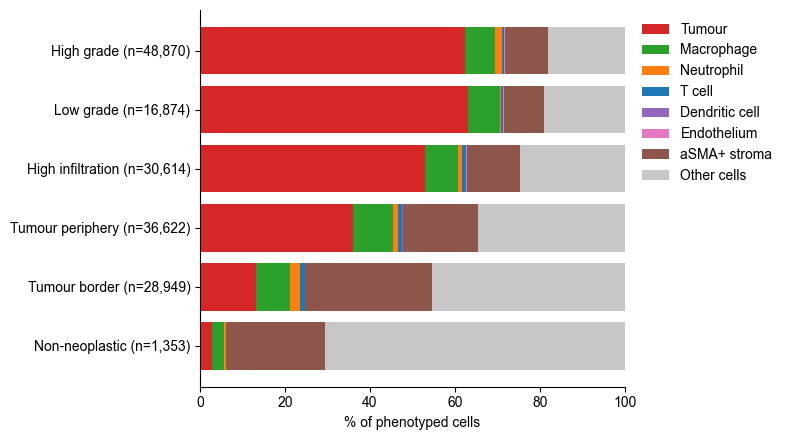

In [25]:
comp = pd.crosstab(ph['sample_type'], ph['phenotype'], normalize='index').mul(100)
comp = comp.reindex(index=[s for s in SAMPLE_ORDER if s in comp.index],
                    columns=[o for o in ORDER if o in comp.columns])
n = ph.groupby('sample_type').size()

fig, ax = plt.subplots(figsize=(8, 4.5))
left = np.zeros(len(comp))
for p in comp.columns:
    ax.barh(range(len(comp)), comp[p], left=left, color=COLOURS[p], label=p)
    left += comp[p].to_numpy()
ax.set_yticks(range(len(comp)))
ax.set_yticklabels([f'{s} (n={n[s]:,})' for s in comp.index])
ax.invert_yaxis()
ax.set_xlabel('% of phenotyped cells')
ax.set_xlim(0, 100)
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
fig.tight_layout()
fig.savefig(OUT / 'composition_by_sample_type.png', dpi=200, bbox_inches='tight')

Mean marker expression per phenotype (arcsinh, scaled 0–1 per marker).

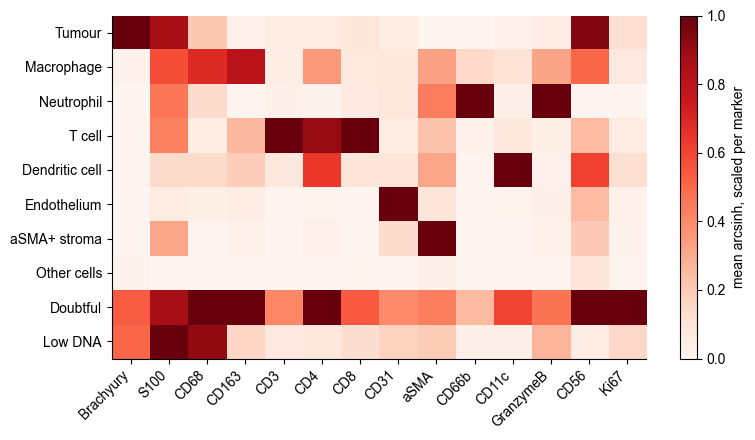

In [26]:
hm_markers = LINEAGE + ['GranzymeB', 'CD56', 'Ki67']
hm = np.arcsinh(df.groupby('phenotype')[hm_markers].mean())
hm = hm.reindex([o for o in ORDER if o in hm.index])
hm = (hm - hm.min()) / (hm.max() - hm.min())

fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(hm.to_numpy(), cmap='Reds', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(len(hm_markers)))
ax.set_xticklabels([m.replace('Brachiury', 'Brachyury') for m in hm_markers], rotation=45, ha='right')
ax.set_yticks(range(len(hm)))
ax.set_yticklabels(hm.index)
fig.colorbar(im, ax=ax, label='mean arcsinh, scaled per marker')
fig.tight_layout()
fig.savefig(OUT / 'marker_heatmap.png', dpi=200, bbox_inches='tight')

Cell maps: phenotypes painted on the segmentation mask of K9 (tumour border) and K1 (high grade).

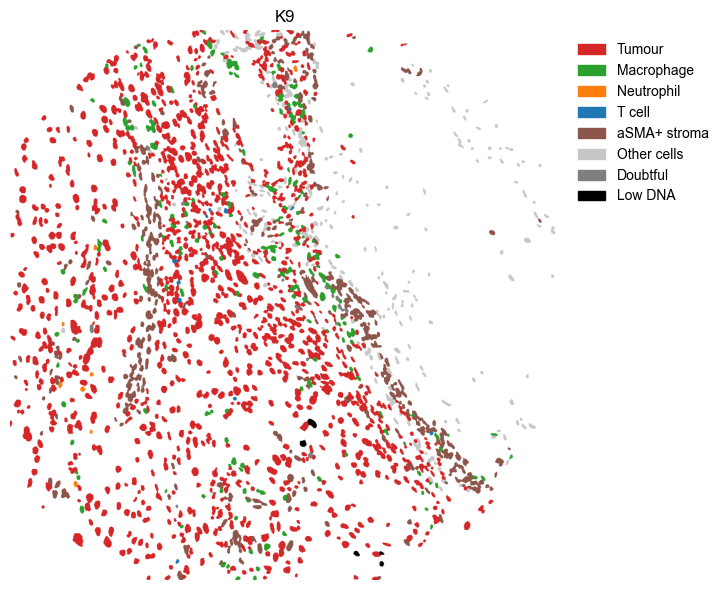

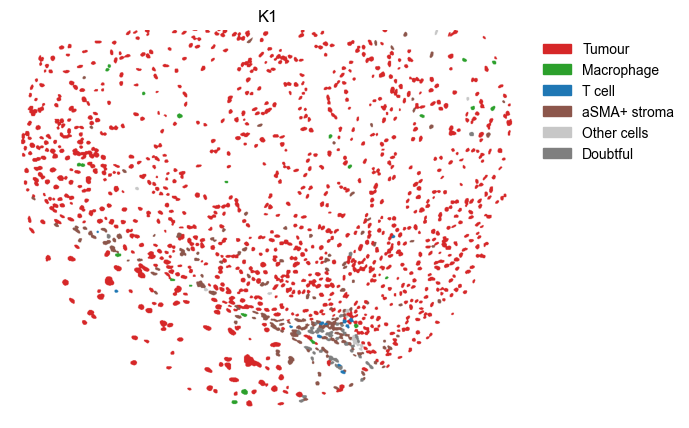

In [27]:
for roi in ['ROI003_K9', 'ROI142_K1']:
    mask = tifffile.imread(WORKFLOW_DIR / 'data/masks' / f'{roi}.tiff')
    sub = df[df['Image'] == roi].set_index('Object')['phenotype']
    lut = np.ones((int(mask.max()) + 1, 3))
    for obj, p in sub.items():
        lut[obj] = matplotlib.colors.to_rgb(COLOURS[p])

    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(lut[mask])
    ax.set_axis_off()
    ax.set_title(roi.split('_')[1])
    ax.legend(handles=[matplotlib.patches.Patch(color=COLOURS[p], label=p) for p in ORDER if p in set(sub)],
              bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
    fig.tight_layout()
    fig.savefig(OUT / f'cell_map_{roi}.png', dpi=200, bbox_inches='tight')

In [29]:
import napari, pandas as pd, tifffile
from napari.utils.colormaps import DirectLabelColormap

W = '/Users/rashid/1_IMC_Analysis/11_Vincenzo/261107_CH_Cellpose'
roi = 'ROI003_K9'
COLOURS = {'Tumour': '#d62728', 'Macrophage': '#2ca02c', 'Neutrophil': '#ff7f0e', 'T cell': '#1f77b4',
           'Dendritic cell': '#9467bd', 'Endothelium': '#e377c2', 'aSMA+ stroma': '#8c564b',
           'Other cells': '#c7c7c7', 'Mixed signal': '#7f7f7f', 'Low DNA': '#000000'}

mask = tifffile.imread(f'{W}/data/masks/{roi}.tiff')
img = tifffile.imread(f'{W}/data/img/{roi}.tiff')
panel = pd.read_csv(f'{W}/data/panel.csv').query('keep == 1').reset_index(drop=True)
ph = pd.read_csv(f'{W}/results/phenotyping_preliminary/preliminary_phenotypes.csv').query('Image == @roi')

colours = {obj: COLOURS[p] for obj, p in zip(ph['Object'], ph['phenotype'])}
colours[0] = 'transparent'
colours[None] = 'transparent'

v = napari.Viewer()
for m in ['DNA1', 'Brachiury', 'CD68', 'aSMA']:
    v.add_image(img[panel.index[panel['name'] == m][0]], name=m, blending='additive',
                colormap='gray', visible=(m == 'DNA1'), contrast_limits=(0, 10))
v.add_labels(mask, name='phenotypes', colormap=DirectLabelColormap(color_dict=colours), opacity=0.8)
napari.run()


In [30]:
import numpy as np

v = napari.Viewer()
for m in ['DNA1', 'Brachiury', 'CD68', 'aSMA']:
    v.add_image(img[panel.index[panel['name'] == m][0]], name=m, blending='additive',
                colormap='gray', visible=(m == 'DNA1'), contrast_limits=(0, 10))

for p in reversed(list(COLOURS)):
    cells_p = ph.loc[ph['phenotype'] == p, 'Object'].to_numpy()
    if len(cells_p) == 0:
        continue
    layer_mask = np.where(np.isin(mask, cells_p), mask, 0)
    cmap = DirectLabelColormap(color_dict={None: COLOURS[p], 0: 'transparent'})
    v.add_labels(layer_mask, name=f'{p} ({len(cells_p)})', colormap=cmap, opacity=0.8)

napari.run()
